# Customer Engagement Clustering – Facebook Live Sellers

**Goal:** Group Facebook posts of Thai online sellers by **engagement pattern** (reactions, comments, shares…) with K-Means.

**Dataset:** `Live.csv` – 7,050 posts (UCI *Facebook Live Sellers in Thailand*)

**Approach:** Drop empty / ID columns → encode `status_type` → RobustScaler / StandardScaler → choose *K* with the elbow method and silhouette score → K-Means → visualize clusters with PCA (2D).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Load the data

In [2]:
df=pd.read_csv('../data/Live.csv')

In [3]:
df

,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,246675545449582_1649696485147474,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,246675545449582_1649426988507757,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,246675545449582_1648730588577397,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,246675545449582_1648576705259452,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,246675545449582_1645700502213739,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7045,1050855161656896_1061863470556065,photo,9/24/2016 2:58,89,0,0,89,0,0,0,0,0,NaN,NaN,NaN,NaN
7046,1050855161656896_1061334757275603,photo,9/23/2016 11:19,16,0,0,14,1,0,1,0,0,NaN,NaN,NaN,NaN
7047,1050855161656896_1060126464063099,photo,9/21/2016 23:03,2,0,0,1,1,0,0,0,0,NaN,NaN,NaN,NaN
7048,1050855161656896_1058663487542730,photo,9/20/2016 0:43,351,12,22,349,2,0,0,0,0,NaN,NaN,NaN,NaN


## Exploratory data analysis

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   object 
 1   status_type       7050 non-null   object 
 2   status_published  7050 non-null   object 
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(9), object(3)
memory 

In [5]:
df.shape

(7050, 16)

In [6]:
df.isnull().sum()

status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64

In [7]:
df = df.drop(columns=['Column1', 'Column2', 'Column3', 'Column4'])

## Data cleaning & preprocessing

In [8]:
df = pd.get_dummies(df, columns=['status_type'], drop_first=True)

In [9]:
df = df.drop(columns=['status_published'])

In [10]:
df = df.drop(columns=['status_id'])

In [11]:
df

,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,status_type_photo,status_type_status,status_type_video
0,529,512,262,432,92,3,1,1,0,False,False,True
1,150,0,0,150,0,0,0,0,0,True,False,False
2,227,236,57,204,21,1,1,0,0,False,False,True
3,111,0,0,111,0,0,0,0,0,True,False,False
4,213,0,0,204,9,0,0,0,0,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
7045,89,0,0,89,0,0,0,0,0,True,False,False
7046,16,0,0,14,1,0,1,0,0,True,False,False
7047,2,0,0,1,1,0,0,0,0,True,False,False
7048,351,12,22,349,2,0,0,0,0,True,False,False


## Feature distributions

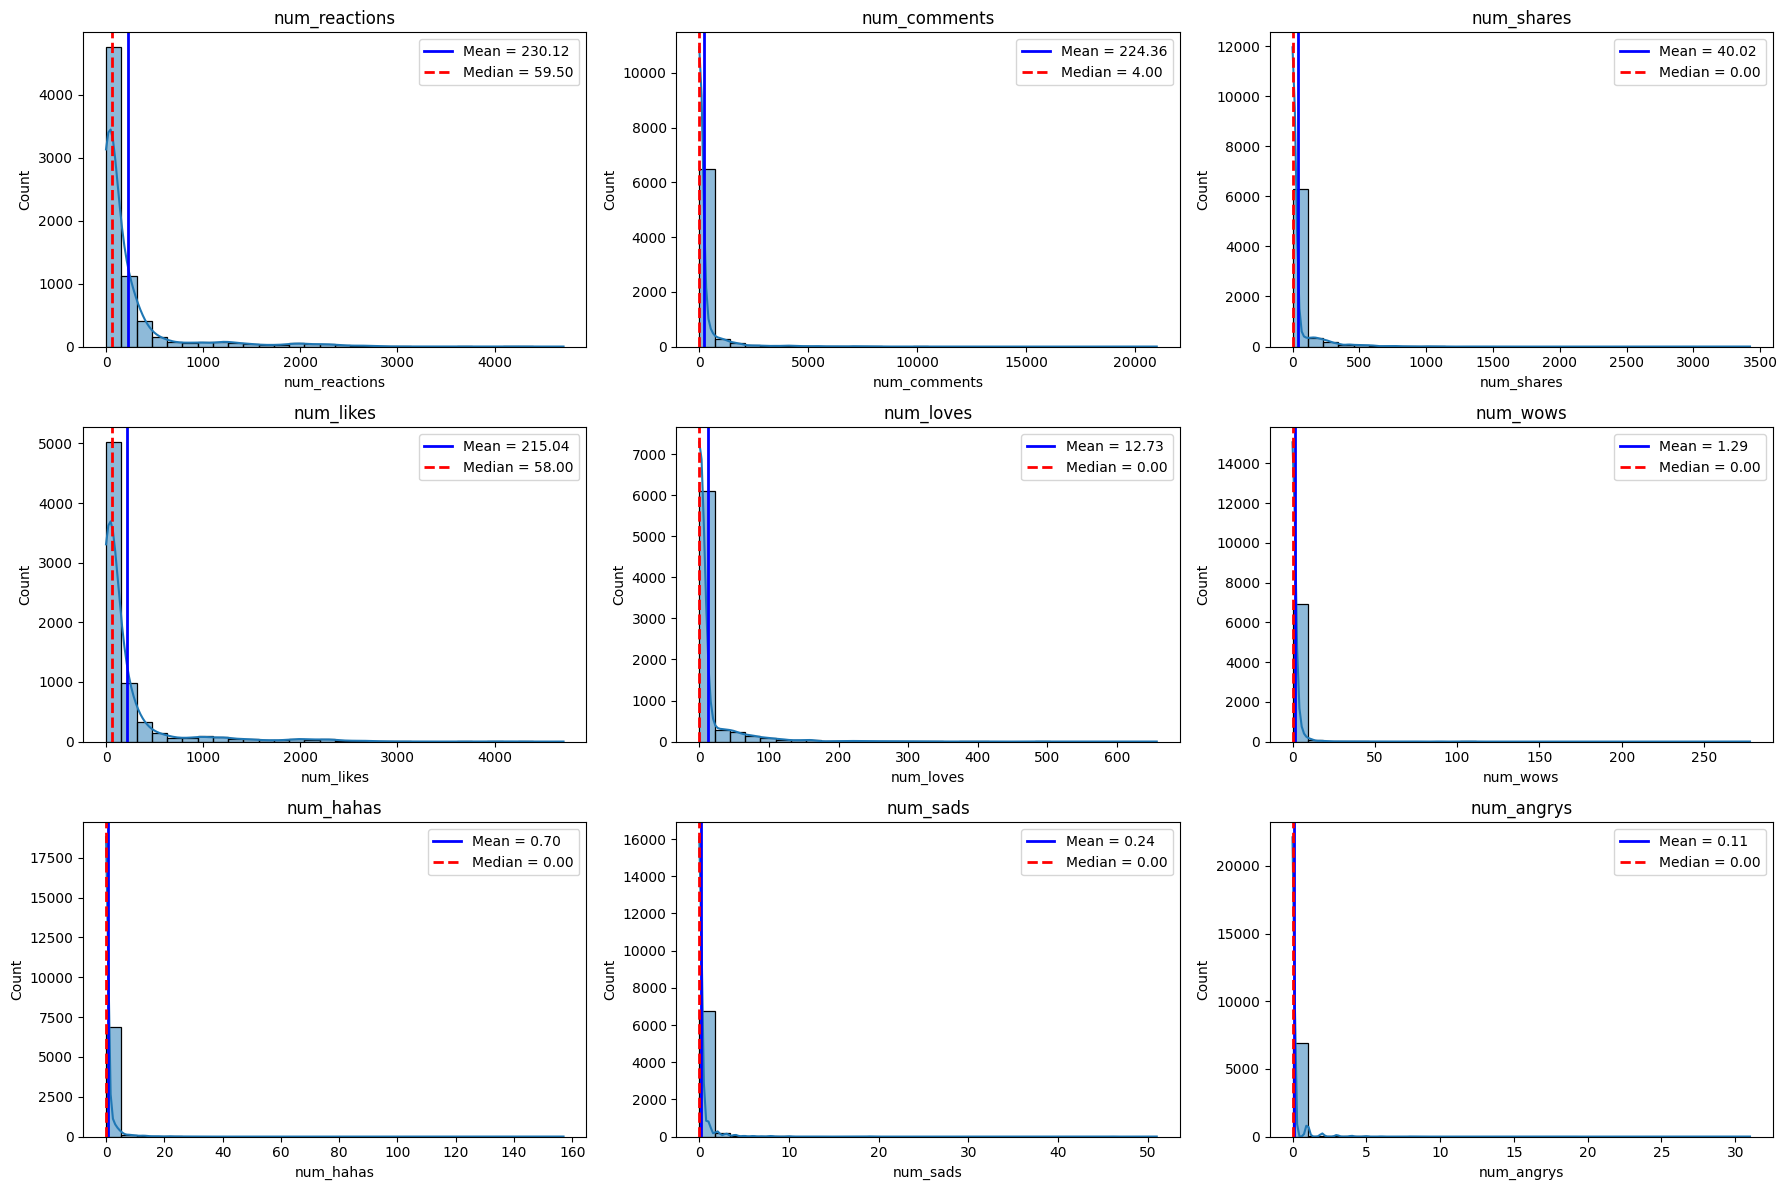

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Numeric columns only
numeric_df = df.select_dtypes(include=['int64', 'float64'])

features = numeric_df.columns

n_cols = 3
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(features):

    sns.histplot(
        data=numeric_df,
        x=col,
        kde=True,
        bins=30,
        ax=axes[i]
    )

    mean_val = numeric_df[col].mean()
    median_val = numeric_df[col].median()

    axes[i].axvline(
        mean_val,
        color='blue',
        linestyle='-',
        linewidth=2,
        label=f"Mean = {mean_val:.2f}"
    )

    axes[i].axvline(
        median_val,
        color='red',
        linestyle='--',
        linewidth=2,
        label=f"Median = {median_val:.2f}"
    )

    axes[i].set_title(col, fontsize=12)
    axes[i].legend()

# Remove empty axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Feature scaling

In [13]:
from sklearn.preprocessing import StandardScaler, RobustScaler


robust_cols = [
    "num_reactions",
    "num_comments",
    "num_shares",
    "num_likes",
    "num_loves",
    "num_wows",
    "num_hahas",
    "num_sads",
    "num_angrys",
    
]



robust_scaler = RobustScaler()



df_scaled = df.copy()


df_scaled[robust_cols] = robust_scaler.fit_transform(df[robust_cols])





df_scaled.head()

,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,status_type_photo,status_type_status,status_type_video
0,2.324257,22.086957,65.50,2.229508,30.666667,3.0,1.0,1.0,0.0,False,False,True
1,0.448020,-0.173913,0.00,0.548435,0.000000,0.0,0.0,0.0,0.0,True,False,False
2,0.829208,10.086957,14.25,0.870343,7.000000,1.0,1.0,0.0,0.0,False,False,True
3,0.254950,-0.173913,0.00,0.315946,0.000000,0.0,0.0,0.0,0.0,True,False,False
4,0.759901,-0.173913,0.00,0.870343,3.000000,0.0,0.0,0.0,0.0,True,False,False


In [14]:
df_scaled

,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,status_type_photo,status_type_status,status_type_video
0,2.324257,22.086957,65.50,2.229508,30.666667,3.0,1.0,1.0,0.0,False,False,True
1,0.448020,-0.173913,0.00,0.548435,0.000000,0.0,0.0,0.0,0.0,True,False,False
2,0.829208,10.086957,14.25,0.870343,7.000000,1.0,1.0,0.0,0.0,False,False,True
3,0.254950,-0.173913,0.00,0.315946,0.000000,0.0,0.0,0.0,0.0,True,False,False
4,0.759901,-0.173913,0.00,0.870343,3.000000,0.0,0.0,0.0,0.0,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
7045,0.146040,-0.173913,0.00,0.184799,0.000000,0.0,0.0,0.0,0.0,True,False,False
7046,-0.215347,-0.173913,0.00,-0.262295,0.333333,0.0,1.0,0.0,0.0,True,False,False
7047,-0.284653,-0.173913,0.00,-0.339791,0.333333,0.0,0.0,0.0,0.0,True,False,False
7048,1.443069,0.347826,5.50,1.734724,0.666667,0.0,0.0,0.0,0.0,True,False,False


In [15]:
X = df_scaled

## Choosing K – elbow method & silhouette score

In [16]:
from sklearn.cluster import KMeans

wcss = []
k_range = range(1,11)
for k in k_range:
    kmean = KMeans(n_clusters=k,random_state=42,n_init=10)
    kmean.fit(X)
    wcss.append(kmean.inertia_)

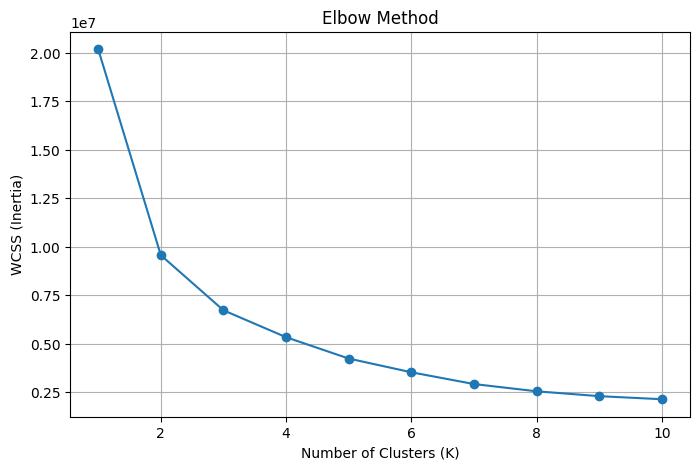

In [17]:
plt.figure(figsize=(8,5))

plt.plot(range(1,11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")

plt.grid(True)
plt.show()

## Final K-Means model & evaluation

In [18]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    score = silhouette_score(X, labels)

    print(f"K = {k} --> Silhouette Score = {score:.4f}")

K = 2 --> Silhouette Score = 0.8891


K = 3 --> Silhouette Score = 0.8526


K = 4 --> Silhouette Score = 0.8261


K = 5 --> Silhouette Score = 0.8327


K = 6 --> Silhouette Score = 0.8279


K = 7 --> Silhouette Score = 0.8279


K = 8 --> Silhouette Score = 0.8185


K = 9 --> Silhouette Score = 0.8199


K = 10 --> Silhouette Score = 0.8229


In [19]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X)

In [20]:
X["Cluster"] = clusters
X["Cluster"].value_counts()

Cluster
0    6740
1     310
Name: count, dtype: int64

## PCA visualization

In [21]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X.drop("Cluster", axis=1))

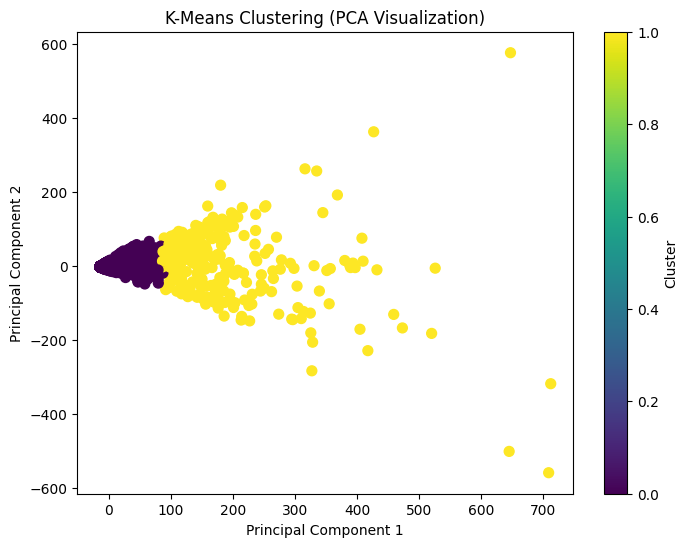

In [22]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering (PCA Visualization)")
plt.colorbar(label="Cluster")
plt.show()

In [23]:
from sklearn.metrics import silhouette_score

score = silhouette_score(
    X.drop("Cluster", axis=1),
    clusters
)

print("Silhouette Score =", score)

Silhouette Score = 0.8891418792469999


## Results & conclusion

* Best silhouette score at **K = 2 (0.89)** – most posts fall into one low-engagement group, with a smaller group of highly engaging posts.
* Silhouette scores stay high (> 0.82) for K = 2…7, so the data has a strong dominant structure; the elbow plot was used together with the silhouette score to pick K.
* PCA (2 components) is used to visualize the clusters in 2D.